In [1]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Iris 데이터 준비
iris = load_iris()
feature_names = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
df = pd.DataFrame(iris.data, columns=feature_names)

# K-means 군집화
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    max_iter=300,
    n_init=10,
    random_state=0
)
df["cluster"] = kmeans.fit_predict(df[feature_names])

# 샘플별 및 전체 실루엣 점수
score_samples = silhouette_samples(df[feature_names], df["cluster"])
df["silhouette_coeff"] = score_samples
average_score = silhouette_score(df[feature_names], df["cluster"])

print("샘플별 실루엣 점수 개수:", score_samples.shape)
print("평균 실루엣 점수:", round(average_score, 3))

df.head()

샘플별 실루엣 점수 개수: (150,)
평균 실루엣 점수: 0.553


,sepal_length,sepal_width,petal_length,petal_width,cluster,silhouette_coeff
0,5.1,3.5,1.4,0.2,1,0.852955
1,4.9,3.0,1.4,0.2,1,0.815495
2,4.7,3.2,1.3,0.2,1,0.829315
3,4.6,3.1,1.5,0.2,1,0.805014
4,5.0,3.6,1.4,0.2,1,0.849302


In [2]:
cluster_silhouette = df.groupby("cluster")["silhouette_coeff"].mean()
print(cluster_silhouette)

cluster
0    0.417320
1    0.798140
2    0.451105
Name: silhouette_coeff, dtype: float64


In [3]:
def visualize_silhouette(cluster_list, X_features):
    """여러 군집 수에 대한 실루엣 그래프를 나란히 그립니다."""
    import matplotlib.cm as cm

    n_cols = len(cluster_list)
    fig, axes = plt.subplots(
        1, n_cols, figsize=(4 * n_cols, 5), squeeze=False
    )
    axes = axes.ravel()

    for ind, n_clusters in enumerate(cluster_list):
        if n_clusters < 2 or n_clusters >= len(X_features):
            raise ValueError("군집 수는 2 이상, 데이터 샘플 수 미만이어야 합니다.")

        clusterer = KMeans(
            n_clusters=n_clusters,
            max_iter=500,
            n_init=10,
            random_state=0
        )
        cluster_labels = clusterer.fit_predict(X_features)
        sil_avg = silhouette_score(X_features, cluster_labels)
        sil_values = silhouette_samples(X_features, cluster_labels)

        ax = axes[ind]
        ax.set_title(
            f"군집 수: {n_clusters}\n평균 실루엣 점수: {sil_avg:.3f}"
        )
        ax.set_xlabel("실루엣 계수")
        ax.set_ylabel("군집")
        ax.set_xlim([-0.1, 1.0])
        ax.set_xticks(np.arange(-0.1, 1.1, 0.2))
        ax.set_yticks([])

        y_lower = 10
        for cluster_id in range(n_clusters):
            cluster_values = sil_values[cluster_labels == cluster_id]
            cluster_values.sort()
            cluster_size = cluster_values.shape[0]
            y_upper = y_lower + cluster_size
            color = cm.nipy_spectral(float(cluster_id) / n_clusters)

            ax.fill_betweenx(
                np.arange(y_lower, y_upper),
                0,
                cluster_values,
                facecolor=color,
                edgecolor=color,
                alpha=0.7
            )
            ax.text(-0.05, y_lower + 0.5 * cluster_size, str(cluster_id))
            y_lower = y_upper + 10

        ax.axvline(x=sil_avg, color="red", linestyle="--", linewidth=1)

    fig.tight_layout()
    plt.show()

c:\Users\Win11Pro\Documents\ML\.venv-machineLearning\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49373 (\N{HANGUL SYLLABLE SAENG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Win11Pro\Documents\ML\.venv-machineLearning\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Win11Pro\Documents\ML\.venv-machineLearning\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 46108 (\N{HANGUL SYLLABLE DOEN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Win11Pro\Documents\ML\.venv-machineLearning\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Win11Pro\Documents\ML\.venv-machineLearning\lib\site-packages\IPyth

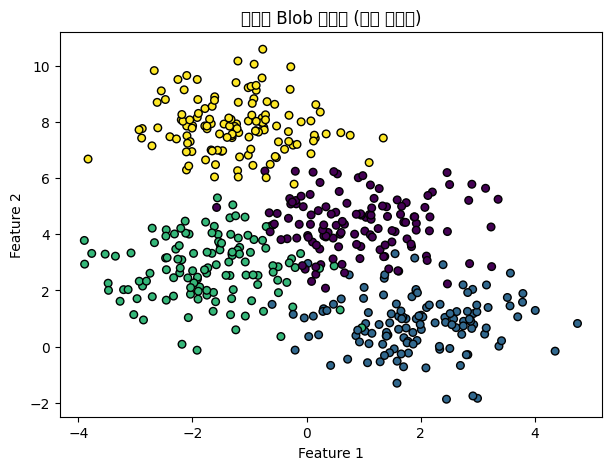

C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_12060\339664642.py:56: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_12060\339664642.py:56: UserWarning: Glyph 47336 (\N{HANGUL SYLLABLE RU}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_12060\339664642.py:56: UserWarning: Glyph 50659 (\N{HANGUL SYLLABLE ES}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_12060\339664642.py:56: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_12060\339664642.py:56: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_12060\339664642.py:56: UserWarning: Glyph 44400 (\N{HANGUL SYLLABLE GUN}) mi

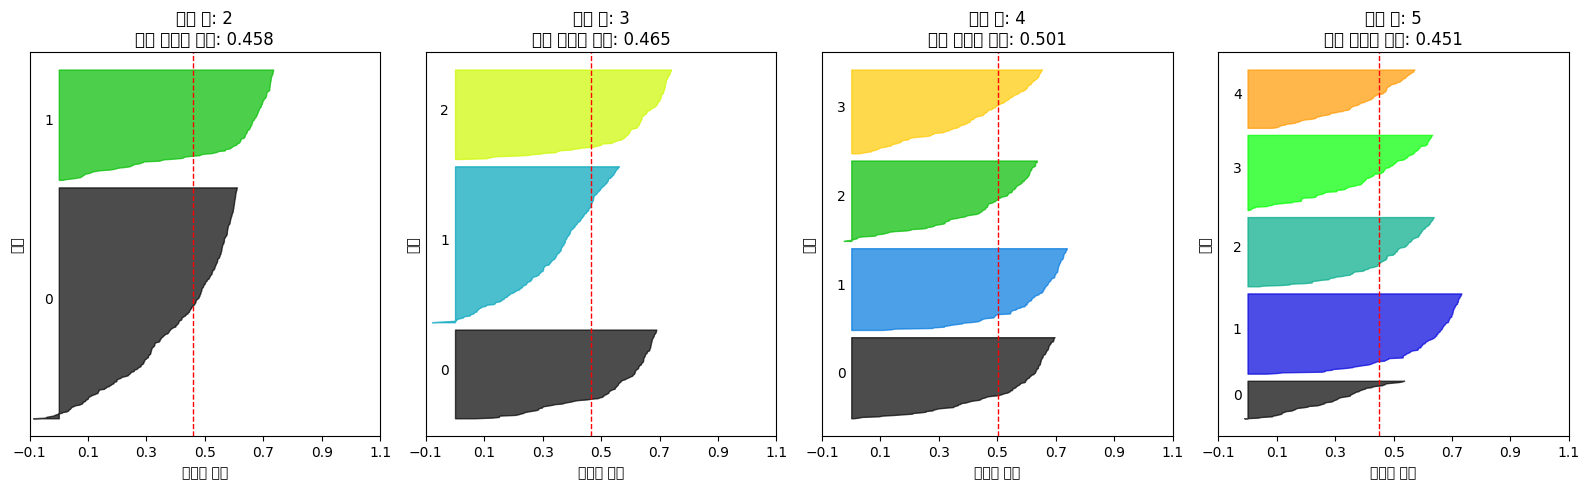

In [4]:
from sklearn.datasets import make_blobs

# 중심이 분리된 4개 군집의 샘플 데이터 생성
X, y = make_blobs(
    n_samples=500,
    n_features=2,
    centers=4,
    cluster_std=1.0,
    center_box=(-10.0, 10.0),
    shuffle=True,
    random_state=0
)

# 실제 생성 군집 확인
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=30, edgecolor="k")
plt.title("생성된 Blob 데이터 (실제 레이블)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 군집 수에 따른 실루엣 그래프 비교
visualize_silhouette([2, 3, 4, 5], X)

C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_12060\339664642.py:56: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_12060\339664642.py:56: UserWarning: Glyph 47336 (\N{HANGUL SYLLABLE RU}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_12060\339664642.py:56: UserWarning: Glyph 50659 (\N{HANGUL SYLLABLE ES}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_12060\339664642.py:56: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_12060\339664642.py:56: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_12060\339664642.py:56: UserWarning: Glyph 44400 (\N{HANGUL SYLLABLE GUN}) mi

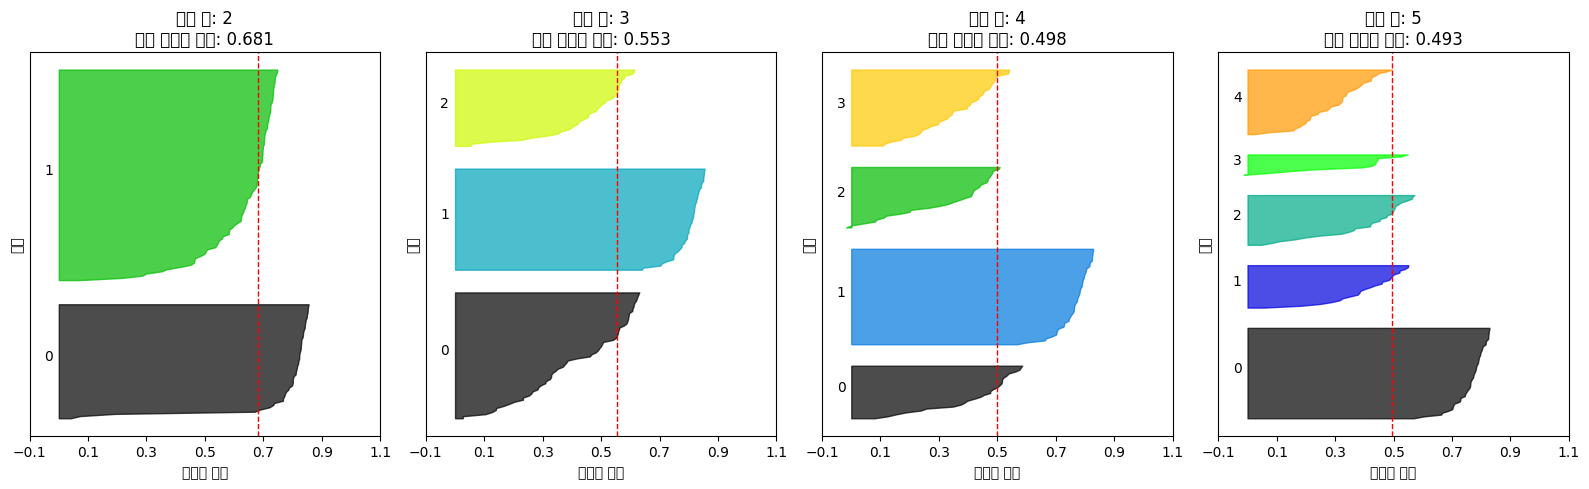

In [5]:
from sklearn.datasets import load_iris
iris=load_iris()
visualize_silhouette([2,3,4,5],iris.data)
